# Analisis Statistika Deskriptif Kondisi Fisik Berbasis Sensor Wearable pada Berbagai Tingkat Stres Mahasiswa
**Sumber data:** SSAQS – Zenodo (https://zenodo.org/records/18706837) · **Unit observasi:** mahasiswa-hari (satu baris = data satu mahasiswa pada satu hari)

## Rumusan masalah
1. Bagaimana distribusi frekuensi tingkat stres mahasiswa (rendah, sedang, tinggi)?
2. Berapa rata-rata dan penyebaran (standar deviasi, varians, dan standard error) HRV, skor tidur, durasi tidur dalam, dan jumlah langkah kaki mahasiswa pada setiap tingkat stres?
3. Bagaimana keragaman relatif (koefisien variasi) dan bentuk distribusi (skewness dan kurtosis) dari setiap variabel kondisi fisik mahasiswa?

## Tujuan
1. Menyajikan distribusi frekuensi dan persentase tingkat stres mahasiswa dalam bentuk tabel dan grafik.
2. Menghitung rata-rata, standar deviasi, varians, dan standard error HRV, skor tidur, durasi tidur dalam, dan jumlah langkah kaki pada setiap tingkat stres. *
3. Menghitung koefisien variasi, skewness, dan kurtosis setiap variabel kondisi fisik, serta menggambarkan bentuk distribusinya dengan histogram.

## A. Pengorganisasian Data

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = lambda x: f"{x:.0f}" if float(x).is_integer() else f"{x:.3f}"
pd.options.display.width = 200

OUT = "hasil"
os.makedirs(OUT, exist_ok=True)

In [4]:
from google.colab import files
path = files.upload()

Saving 3TIB_07_StresMahasiswaWearable.xlsx to 3TIB_07_StresMahasiswaWearable (1).xlsx


In [5]:
dataraw = pd.read_excel(list(path.keys())[0])
print(dataraw)

      id_mahasiswa    tanggal  hrv_rmssd  hrv_low_frequency  hrv_high_frequency  skor_tidur  tidur_dalam_menit  langkah_total  stres_kuesioner  kecemasan_kuesioner  skor_stres_perangkat
0                1 2025-02-23     74.337           2050.754            1687.188          85                 78           4102                4                    7                    58
1                1 2025-02-24     74.538           2048.423            1713.701          82                 88           4729               37                   16                    71
2                1 2025-02-25     68.198           2538.938            1364.187          84                125           5868               34                   13                    71
3                1 2025-02-26     70.309           2410.189            1321.264          81                 71           5896               39                   17                   NaN
4                1 2025-02-28     74.210           2350.062           

### Pemeriksaan data

In [6]:
print("Jumlah baris, kolom :", dataraw.shape)
print("Jumlah mahasiswa    :", dataraw["id_mahasiswa"].nunique())
print("Rentang tanggal     :", dataraw["tanggal"].min().date(), "s.d.", dataraw["tanggal"].max().date())
print("\nTipe data:\n", dataraw.dtypes)
print("\nMissing value per kolom:\n", dataraw.isna().sum())

Jumlah baris, kolom : (1371, 11)
Jumlah mahasiswa    : 32
Rentang tanggal     : 2025-02-18 s.d. 2025-06-30

Tipe data:
 id_mahasiswa                     int64
tanggal                 datetime64[ns]
hrv_rmssd                      float64
hrv_low_frequency              float64
hrv_high_frequency             float64
skor_tidur                       int64
tidur_dalam_menit                int64
langkah_total                    int64
stres_kuesioner                  int64
kecemasan_kuesioner              int64
skor_stres_perangkat           float64
dtype: object

Missing value per kolom:
 id_mahasiswa              0
tanggal                   0
hrv_rmssd                 0
hrv_low_frequency         0
hrv_high_frequency        0
skor_tidur                0
tidur_dalam_menit         0
langkah_total             0
stres_kuesioner           0
kecemasan_kuesioner       0
skor_stres_perangkat    370
dtype: int64


### Variabel yang dianalisis dan fungsi statistika deskriptif

In [7]:
VAR = {"hrv_rmssd": "HRV RMSSD (ms)", "skor_tidur": "Skor tidur",
       "tidur_dalam_menit": "Tidur dalam (menit)", "langkah_total": "Langkah kaki"}
VAR_ALL = {**VAR, "stres_kuesioner": "Skor stres kuesioner"}

for v in VAR_ALL:
    dataraw[v] = pd.to_numeric(dataraw[v], errors="coerce")

dt = dataraw["hrv_rmssd"]
stats = dt.describe().drop(["25%", "50%", "75%"])
stats["Standard Error"] = dt.sem()
stats["Median"]         = dt.median()
stats["variance"]       = dt.var()
stats["range"]          = dt.max() - dt.min()
stats["skewness"]       = dt.skew()
stats["kurtosis"]       = dt.kurtosis()
stats["CV (%)"]         = dt.std() / dt.mean() * 100
print(stats)

count                1371
mean               75.827
std                34.633
min                19.313
max               181.186
Standard Error      0.935
Median             70.019
variance         1199.412
range             161.873
skewness            0.700
kurtosis           -0.282
CV (%)             45.673
Name: hrv_rmssd, dtype: float64


In [8]:
def deskriptif(dt):
    stats = dt.describe().drop(["25%", "50%", "75%"])
    stats["Standard Error"] = dt.sem()
    stats["Median"]         = dt.median()
    stats["variance"]       = dt.var()
    stats["range"]          = dt.max() - dt.min()
    stats["skewness"]       = dt.skew()
    stats["kurtosis"]       = dt.kurtosis()
    stats["CV (%)"]         = dt.std() / dt.mean() * 100
    return stats


print(deskriptif(dataraw["hrv_rmssd"]))

count                1371
mean               75.827
std                34.633
min                19.313
max               181.186
Standard Error      0.935
Median             70.019
variance         1199.412
range             161.873
skewness            0.700
kurtosis           -0.282
CV (%)             45.673
Name: hrv_rmssd, dtype: float64


### Pemeriksaan nilai ekstrem

In [9]:
ekstrem = {}
for v in VAR_ALL:
    z = (dataraw[v] - dataraw[v].mean()) / dataraw[v].std()
    ekstrem[v] = [dataraw[v].min(), dataraw[v].max(), int((z.abs() > 3).sum()),
                  round((z.abs() > 3).mean() * 100, 2)]
ekstrem = pd.DataFrame(ekstrem, index=["Min", "Max", "Jumlah |z|>3", "% |z|>3"]).T
print(ekstrem)

                     Min     Max  Jumlah |z|>3  % |z|>3
hrv_rmssd         19.313 181.186             1    0.070
skor_tidur            45      93            12    0.880
tidur_dalam_menit      5     177             4    0.290
langkah_total         18   37022            13    0.950
stres_kuesioner        0     100             0        0


###Jumlah hari pengamatan per mahasiswa

In [10]:
hari_mhs = dataraw.groupby("id_mahasiswa").size()
print("Jumlah mahasiswa     :", hari_mhs.count())
print("Rata-rata hari       : %.2f" % hari_mhs.mean())
print("Standar deviasi hari : %.2f" % hari_mhs.std())
print("Hari terkecil        :", hari_mhs.min(), "| terbesar:", hari_mhs.max())

Jumlah mahasiswa     : 32
Rata-rata hari       : 42.84
Standar deviasi hari : 25.21
Hari terkecil        : 4 | terbesar: 90


### Membuat kategori tingkat stres

In [11]:
dataraw["kategori_stres"] = pd.cut(dataraw["stres_kuesioner"], bins=[-1, 33, 66, 100],
                                   labels=["Rendah", "Sedang", "Tinggi"])
URUT = ["Rendah", "Sedang", "Tinggi"]
WARNA = ["#2A9D8F", "#E9C46A", "#E76F51"]
print(dataraw[["stres_kuesioner", "kategori_stres"]].head())

   stres_kuesioner kategori_stres
0                4         Rendah
1               37         Sedang
2               34         Sedang
3               39         Sedang
4               22         Rendah


## B. Penyajian Data: Distribusi Frekuensi Tingkat Stres (Rumusan Masalah 1)

In [12]:
#Tabel Frekuensi
datafrq = pd.crosstab(index=dataraw["kategori_stres"], columns="Frekuensi")
print(datafrq)

col_0           Frekuensi
kategori_stres           
Rendah                756
Sedang                424
Tinggi                191


In [13]:
tabel_frek = datafrq.copy()
tabel_frek["Persentase (%)"] = (datafrq["Frekuensi"] / datafrq["Frekuensi"].sum() * 100).round(1)
tabel_frek.loc["Total"] = [datafrq["Frekuensi"].sum(), 100.0]
print(tabel_frek)

col_0           Frekuensi  Persentase (%)
kategori_stres                           
Rendah                756          55.100
Sedang                424          30.900
Tinggi                191          13.900
Total                1371             100


### Statistik skor stres kuesioner

In [14]:
desk_stres = deskriptif(dataraw["stres_kuesioner"])
print(desk_stres)

count               1371
mean              36.387
std               24.778
min                    0
max                  100
Standard Error     0.669
Median                31
variance         613.939
range                100
skewness           0.821
kurtosis           0.016
CV (%)            68.096
Name: stres_kuesioner, dtype: float64


### Grafik

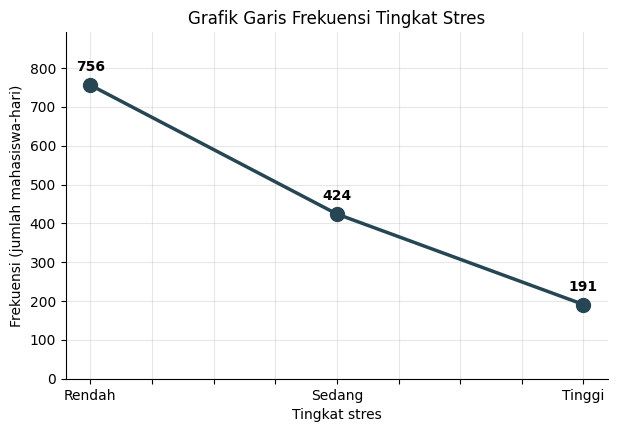

In [15]:
#Grafik Garis
ax = datafrq["Frekuensi"].plot(color="#264653", marker="o", linewidth=2.5, markersize=10,
                               figsize=(7, 4.5), title="Grafik Garis Frekuensi Tingkat Stres")
for i, nilai in enumerate(datafrq["Frekuensi"]):
    ax.annotate(f"{nilai}", (i, nilai), textcoords="offset points", xytext=(0, 10), ha="center", fontweight="bold")
ax.set_xlabel("Tingkat stres"); ax.set_ylabel("Frekuensi (jumlah mahasiswa-hari)")
ax.set_ylim(0, datafrq["Frekuensi"].max() * 1.18); ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.savefig(f"{OUT}/1a_grafik_garis.png", dpi=150, bbox_inches="tight"); plt.show()

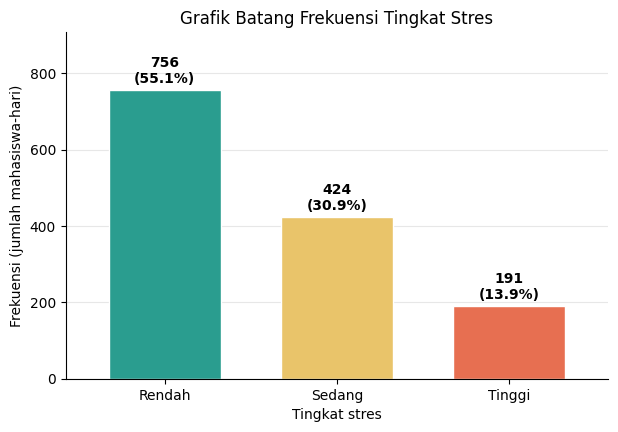

In [16]:
#Grafik Batang
ax = datafrq["Frekuensi"].plot(kind="bar", color=WARNA, edgecolor="white", width=0.65,
                               figsize=(7, 4.5), title="Grafik Batang Frekuensi Tingkat Stres")
label = [f"{n}\n({n / datafrq['Frekuensi'].sum() * 100:.1f}%)" for n in datafrq["Frekuensi"]]
ax.bar_label(ax.containers[0], labels=label, fontweight="bold", padding=3)
ax.set_xlabel("Tingkat stres"); ax.set_ylabel("Frekuensi (jumlah mahasiswa-hari)")
ax.set_ylim(0, datafrq["Frekuensi"].max() * 1.2); ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
plt.savefig(f"{OUT}/1b_grafik_batang.png", dpi=150, bbox_inches="tight"); plt.show()

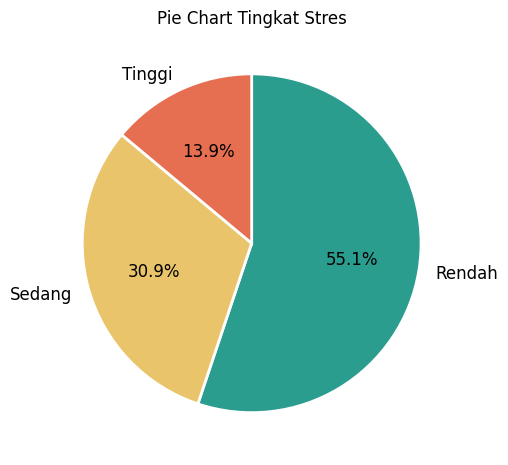

In [17]:
#Pie Chart
datafrq.plot(kind="pie", y="Frekuensi", autopct="%1.1f%%", legend=False, colors=WARNA,
             startangle=90, counterclock=False, wedgeprops={"edgecolor": "white", "linewidth": 2},
             textprops={"fontsize": 12}, figsize=(5.5, 5.5), title="Pie Chart Tingkat Stres")
plt.ylabel("")
plt.savefig(f"{OUT}/1c_pie_chart.png", dpi=150, bbox_inches="tight"); plt.show()

**Kesimpulan RM 1:** dari 1.371 observasi, 756 observasi (55,1%) berada pada tingkat stres **rendah**, 424 observasi (30,9%) **sedang**, dan 191 observasi (13,9%) **tinggi**. Semakin tinggi tingkat stres, semakin sedikit observasinya. Rata-rata skor stres kuesioner 36,39 (median 31) dengan standar deviasi 24,78 (CV 68,1%) dan skewness 0,82, artinya sebagian besar skor berada di nilai rendah dengan ekor panjang ke skor tinggi.

## C. Rata-rata dan Penyebaran Kondisi Fisik per Tingkat Stres (Rumusan Masalah 2)


In [18]:
kolom_rm2 = ["count", "mean", "Median", "std", "variance", "Standard Error"]
desk_kat = {}
for v in VAR:
    per_kat = dataraw.groupby("kategori_stres", observed=True)[v].apply(deskriptif).unstack().loc[URUT]
    per_kat.loc["Keseluruhan"] = deskriptif(dataraw[v])
    desk_kat[v] = per_kat
    print(f"--- {VAR[v]} ---")
    print(per_kat[kolom_rm2], "\n")

--- HRV RMSSD (ms) ---
                count   mean  Median    std  variance  Standard Error
kategori_stres                                                       
Rendah            756 75.429  67.389 35.763  1278.992           1.301
Sedang            424 77.839  73.343 33.922  1150.674           1.647
Tinggi            191 72.937  71.072 31.405   986.256           2.272
Keseluruhan      1371 75.827  70.019 34.633  1199.412           0.935 

--- Skor tidur ---
                count   mean  Median   std  variance  Standard Error
kategori_stres                                                      
Rendah            756 76.146      77 8.182    66.948           0.298
Sedang            424 76.307      77 7.943    63.097           0.386
Tinggi            191 76.021      77 7.706    59.379           0.558
Keseluruhan      1371 76.178      77 8.039    64.621           0.217 

--- Tidur dalam (menit) ---
                count   mean  Median    std  variance  Standard Error
kategori_stres        


### Ringkasan rata-rata dan standar deviasi dalam satu tabel


In [19]:
ringkas = pd.DataFrame({VAR[v]: desk_kat[v]["mean"].round(2).astype(str) + " ± " + desk_kat[v]["std"].round(2).astype(str)
                        for v in VAR})
print(ringkas)

               HRV RMSSD (ms)    Skor tidur Tidur dalam (menit)       Langkah kaki
kategori_stres                                                                    
Rendah          75.43 ± 35.76  76.15 ± 8.18         79.4 ± 24.7  9207.01 ± 5470.72
Sedang          77.84 ± 33.92  76.31 ± 7.94       78.18 ± 25.74  9417.63 ± 5513.97
Tinggi           72.94 ± 31.4  76.02 ± 7.71        79.5 ± 27.11   9708.3 ± 5640.12
Keseluruhan     75.83 ± 34.63  76.18 ± 8.04       79.04 ± 25.36  9341.98 ± 5506.67


### Grafik rata-rata ± standar deviasi per tingkat stres

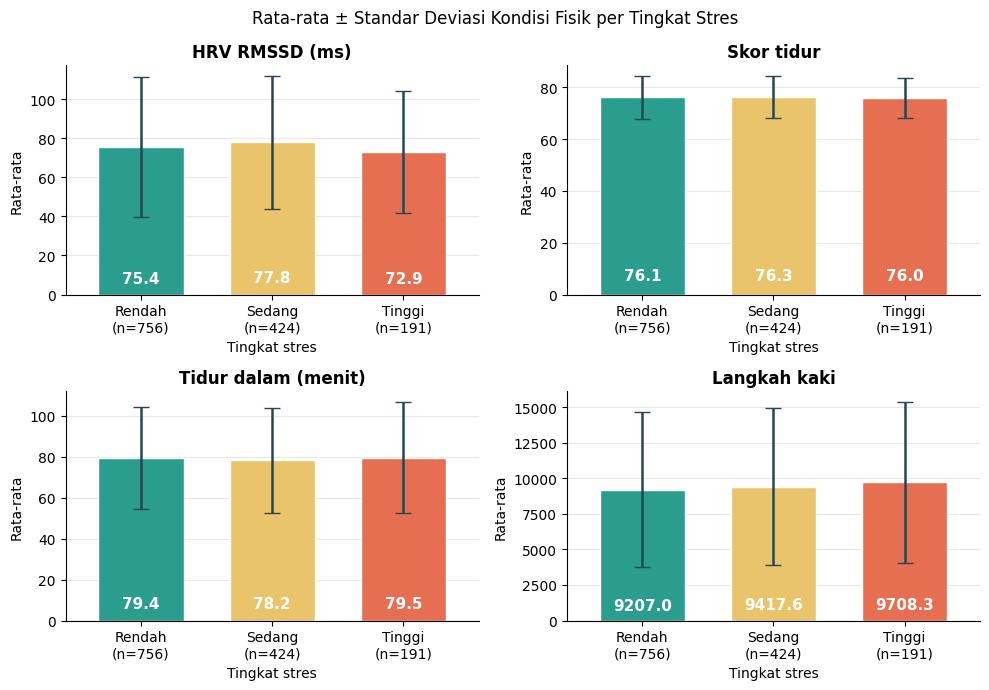

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (v, nama) in zip(axes.ravel(), VAR.items()):
    tabel = desk_kat[v].loc[URUT]
    tabel["mean"].plot(kind="bar", yerr=tabel["std"], capsize=6, color=WARNA, edgecolor="white", width=0.65, ax=ax,
                       error_kw={"elinewidth": 1.8, "ecolor": "#264653"})
    for i, m in enumerate(tabel["mean"]):
        ax.text(i, m * 0.06, f"{m:.1f}", ha="center", va="bottom", color="white", fontweight="bold", fontsize=11)
    ax.set_xticklabels([f"{k}\n(n={int(n)})" for k, n in zip(URUT, tabel["count"])], rotation=0)
    ax.set_title(nama, fontweight="bold"); ax.set_xlabel("Tingkat stres"); ax.set_ylabel("Rata-rata")
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Rata-rata ± Standar Deviasi Kondisi Fisik per Tingkat Stres")
plt.tight_layout()
plt.savefig(f"{OUT}/2_rata_rata_sd.png", dpi=150, bbox_inches="tight"); plt.show()

In [21]:
se_tabel = pd.DataFrame({VAR[v]: desk_kat[v]["Standard Error"] for v in VAR})
print(se_tabel)

                HRV RMSSD (ms)  Skor tidur  Tidur dalam (menit)  Langkah kaki
kategori_stres                                                               
Rendah                   1.301       0.298                0.898       198.968
Sedang                   1.647       0.386                1.250       267.782
Tinggi                   2.272       0.558                1.962       408.105
Keseluruhan              0.935       0.217                0.685       148.720


**Kesimpulan RM 2:**
- **HRV RMSSD (ms):** rata-rata 75,43 (rendah), 77,84 (sedang), 72,94 (tinggi) dengan SD 35,76; 33,92; 31,40 dan varians 1.278,99; 1.150,67; 986,26.
- **Skor tidur:** rata-rata 76,15; 76,31; 76,02 dengan SD 8,18; 7,94; 7,71 dan varians 66,95; 63,10; 59,38.
- **Tidur dalam (menit):** rata-rata 79,40; 78,18; 79,50 dengan SD 24,70; 25,74; 27,11 dan varians 610,00; 662,64; 734,99.
- **Langkah kaki:** rata-rata 9.207,01; 9.417,63; 9.708,30 dengan SD 5.470,72; 5.513,97; 5.640,12.
- **Median** sebagai pelengkap rata-rata: HRV 67,39 (rendah), 73,34 (sedang), 71,07 (tinggi); skor tidur 77 pada ketiga kelompok; tidur dalam 79; 79; 78 menit; langkah kaki 8.182,5; 8.702,5; 8.795. Pada HRV dan langkah kaki, median lebih kecil daripada rata-rata di semua tingkat stres (misalnya HRV stres rendah: rata-rata 75,43 vs median 67,39).
- Pada semua variabel, selisih rata-rata antar tingkat stres jauh lebih kecil daripada standar deviasinya (misalnya HRV: selisih terbesar 4,90 ms sedangkan SD sekitar 31–36 ms), sehingga rata-rata kondisi fisik tampak hampir sama di ketiga tingkat stres. Median memberi gambaran serupa: selisih antar kelompok kecil, dan pada HRV urutannya tidak searah dengan rata-rata (rata-rata terendah pada stres tinggi, median terendah pada stres rendah). Langkah kaki naik tipis dari stres rendah ke tinggi pada rata-rata maupun median, tetapi selisihnya kecil dibanding sebarannya. Ini adalah gambaran deskriptif dan tidak diuji secara statistik.
- Standard error paling kecil pada kelompok rendah dan paling besar pada kelompok tinggi (misalnya HRV: 1,30; 1,65; 2,27) karena jumlah observasi kelompok tinggi paling sedikit.

## D. Keragaman Relatif dan Bentuk Distribusi (Rumusan Masalah 3)

In [22]:
def arah_bentuk(s):
    a = abs(s)
    if a <= 0.5:
        return "sangat mendekati simetris"
    tingkat = "cukup dekat simetris" if a <= 1 else ("kemencengan sedang, dapat ditoleransi" if a <= 2 else "kemencengan kuat")
    return tingkat + (", ekor ke kanan" if s > 0 else ", ekor ke kiri")

def bentuk_puncak(k):
    a = abs(k)
    if a < 0.25:  return "mendekati 0 (mesokurtik)"
    if a <= 1:    return "sangat dekat normal, sedikit " + ("runcing" if k > 0 else "datar")
    if a <= 2:    return "dapat diterima, lebih " + ("runcing" if k > 0 else "datar")
    return "cenderung runcing/berekor berat" if k > 0 else "cenderung datar"

bentuk = pd.DataFrame({VAR_ALL[v]: deskriptif(dataraw[v]) for v in VAR_ALL}).T[["mean", "std", "CV (%)", "skewness", "kurtosis"]]
bentuk["Bentuk (skewness)"] = bentuk["skewness"].apply(arah_bentuk)
bentuk["Bentuk (kurtosis)"] = bentuk["kurtosis"].apply(bentuk_puncak)
print(bentuk)

                         mean      std  CV (%)  skewness  kurtosis                    Bentuk (skewness)                     Bentuk (kurtosis)
HRV RMSSD (ms)         75.827   34.633  45.673     0.700    -0.282  cukup dekat simetris, ekor ke kanan    sangat dekat normal, sedikit datar
Skor tidur             76.178    8.039  10.553    -0.629     0.557   cukup dekat simetris, ekor ke kiri  sangat dekat normal, sedikit runcing
Tidur dalam (menit)    79.040   25.358  32.082     0.158     0.155            sangat mendekati simetris              mendekati 0 (mesokurtik)
Langkah kaki         9341.985 5506.665  58.945     0.851     0.853  cukup dekat simetris, ekor ke kanan  sangat dekat normal, sedikit runcing
Skor stres kuesioner   36.387   24.778  68.096     0.821     0.016  cukup dekat simetris, ekor ke kanan              mendekati 0 (mesokurtik)


###CV, skewness, dan kurtosis per tingkat stres

In [23]:
for ukuran in ["CV (%)", "skewness", "kurtosis"]:
    tabel = pd.DataFrame({VAR[v]: desk_kat[v][ukuran] for v in VAR})
    print(f"--- {ukuran} ---")
    print(tabel, "\n")

--- CV (%) ---
                HRV RMSSD (ms)  Skor tidur  Tidur dalam (menit)  Langkah kaki
kategori_stres                                                               
Rendah                  47.413      10.745               31.104        59.419
Sedang                  43.579      10.410               32.926        58.549
Tinggi                  43.058      10.136               34.100        58.096
Keseluruhan             45.673      10.553               32.082        58.945 

--- skewness ---
                HRV RMSSD (ms)  Skor tidur  Tidur dalam (menit)  Langkah kaki
kategori_stres                                                               
Rendah                   0.727      -0.582                0.052         0.686
Sedang                   0.622      -0.881                0.125         1.074
Tinggi                   0.752      -0.249                0.549         0.992
Keseluruhan              0.700      -0.629                0.158         0.851 

--- kurtosis ---
           

### Perbandingan mean dan median


In [24]:
banding = pd.DataFrame({VAR_ALL[v]: deskriptif(dataraw[v]) for v in VAR_ALL}).T[["mean", "Median"]]
banding["Mean - Median"] = banding["mean"] - banding["Median"]
print(banding)

                         mean  Median  Mean - Median
HRV RMSSD (ms)         75.827  70.019          5.808
Skor tidur             76.178      77         -0.822
Tidur dalam (menit)    79.040      79          0.040
Langkah kaki         9341.985    8509        832.985
Skor stres kuesioner   36.387      31          5.387


Perbandingan yang sama untuk tiap tingkat stres.

In [25]:
banding_kat = pd.concat({VAR[v]: desk_kat[v][["mean", "Median"]]
                          .assign(**{"Mean - Median": desk_kat[v]["mean"] - desk_kat[v]["Median"]}) for v in VAR})
print(banding_kat)

                                       mean   Median  Mean - Median
                    kategori_stres                                 
HRV RMSSD (ms)      Rendah           75.429   67.389          8.039
                    Sedang           77.839   73.343          4.496
                    Tinggi           72.937   71.072          1.865
                    Keseluruhan      75.827   70.019          5.808
Skor tidur          Rendah           76.146       77         -0.854
                    Sedang           76.307       77         -0.693
                    Tinggi           76.021       77         -0.979
                    Keseluruhan      76.178       77         -0.822
Tidur dalam (menit) Rendah           79.405       79          0.405
                    Sedang           78.182       79         -0.818
                    Tinggi           79.503       78          1.503
                    Keseluruhan      79.040       79          0.040
Langkah kaki        Rendah         9207.013 8182

###Histogram

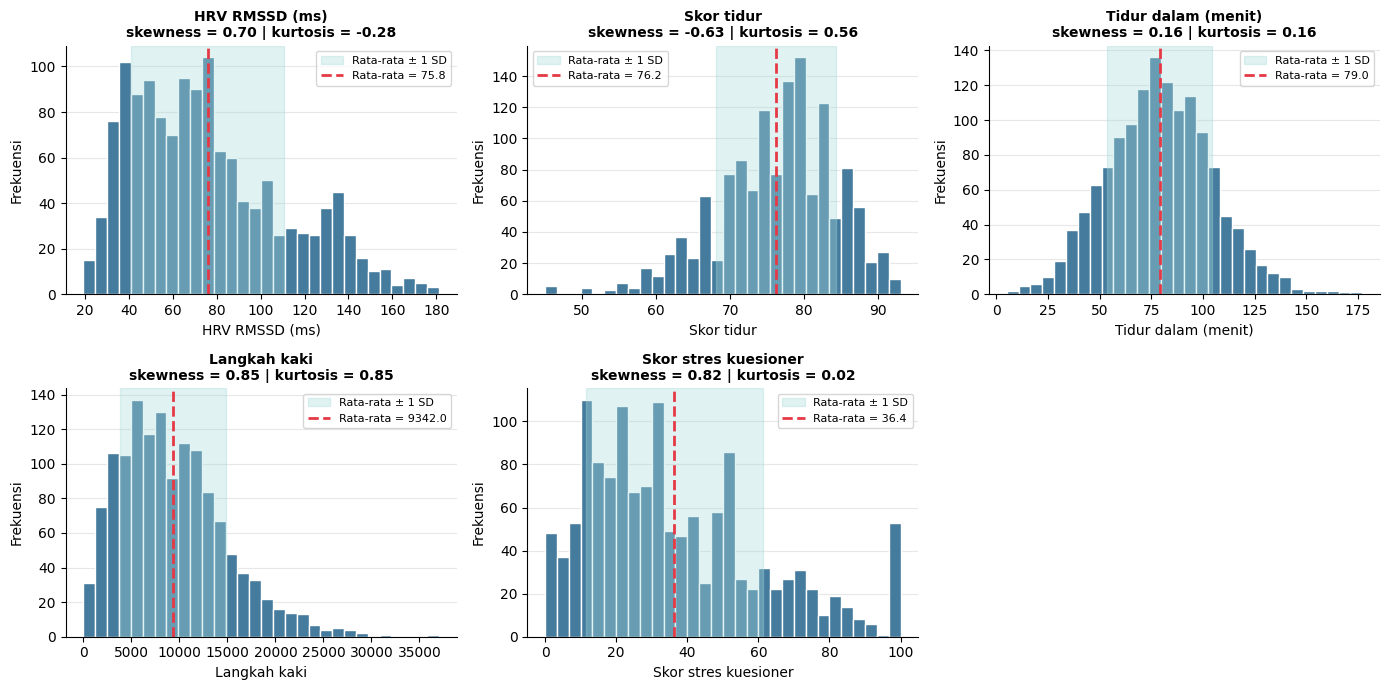

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (v, nama) in zip(axes.ravel(), VAR_ALL.items()):
    dt = dataraw[v]
    dt.plot(kind="hist", bins=30, color="#457B9D", edgecolor="white", ax=ax)
    ax.axvspan(dt.mean() - dt.std(), dt.mean() + dt.std(), color="#A8DADC", alpha=0.35, label="Rata-rata ± 1 SD")
    ax.axvline(dt.mean(), color="#E63946", ls="--", linewidth=2, label=f"Rata-rata = {dt.mean():.1f}")
    ax.set_title(f"{nama}\nskewness = {dt.skew():.2f} | kurtosis = {dt.kurtosis():.2f}", fontsize=10, fontweight="bold")
    ax.set_xlabel(nama); ax.set_ylabel("Frekuensi")
    h, l = ax.get_legend_handles_labels(); ax.legend(*zip(*[(a, b) for a, b in zip(h, l) if b != v]), fontsize=8)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT}/3_histogram_semua.png", dpi=150, bbox_inches="tight"); plt.show()

Histogram per tingkat stres (satu gambar per variabel, tiga panel) untuk melihat apakah bentuk distribusi berbeda antar kelompok.

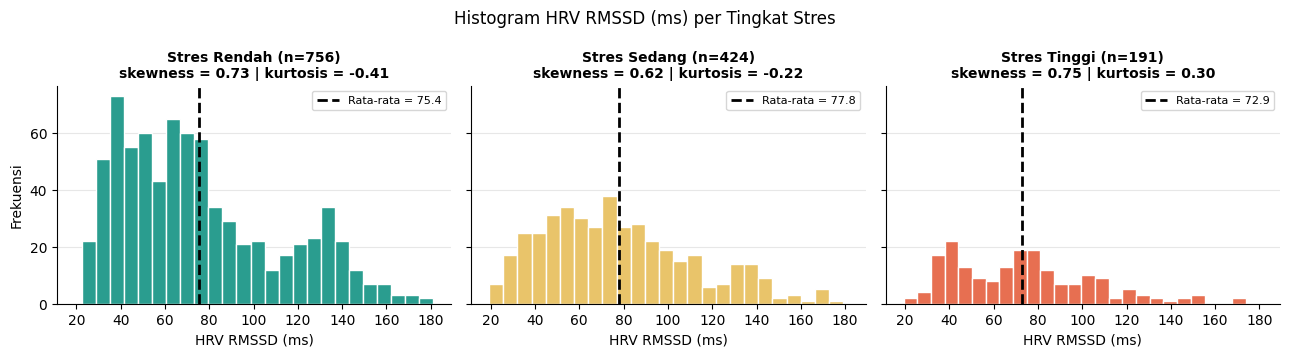

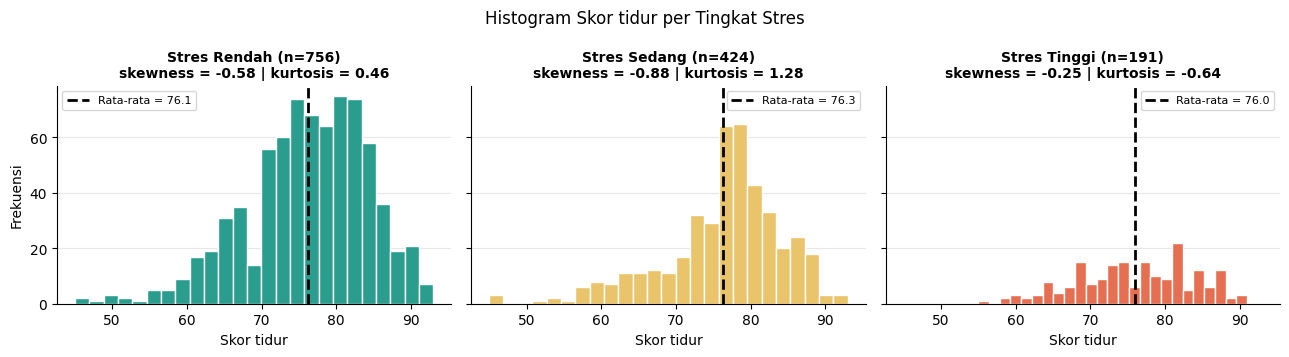

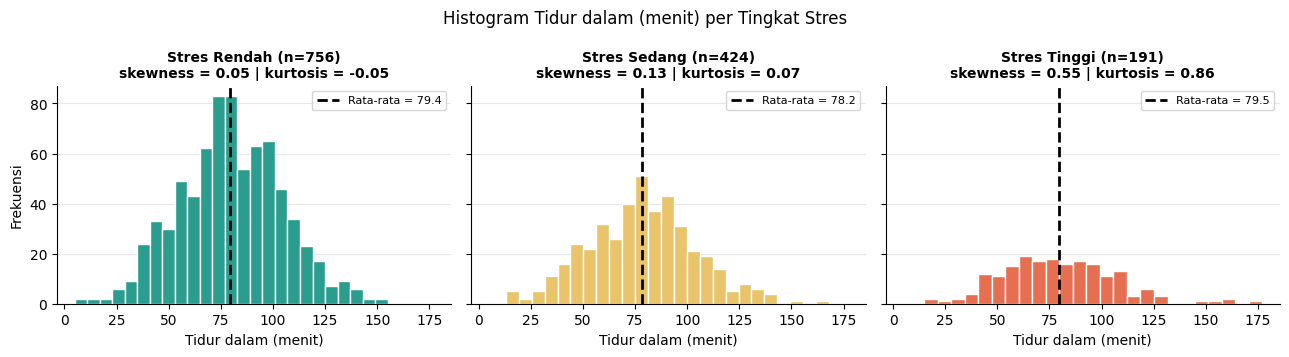

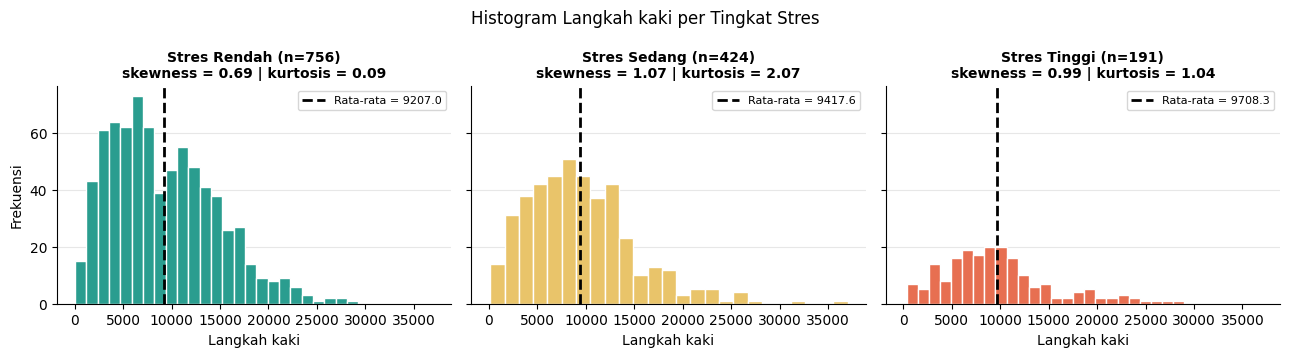

In [27]:
for v, nama in VAR.items():
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)
    for ax, k, w in zip(axes, URUT, WARNA):
        dt = dataraw.loc[dataraw["kategori_stres"] == k, v]
        dt.plot(kind="hist", bins=25, color=w, edgecolor="white", ax=ax)
        ax.axvline(dt.mean(), color="k", ls="--", linewidth=2, label=f"Rata-rata = {dt.mean():.1f}")
        ax.set_title(f"Stres {k} (n={len(dt)})\nskewness = {dt.skew():.2f} | kurtosis = {dt.kurtosis():.2f}", fontsize=10, fontweight="bold")
        ax.set_xlabel(nama); ax.set_ylabel("Frekuensi")
        h, l = ax.get_legend_handles_labels(); ax.legend(*zip(*[(a, b) for a, b in zip(h, l) if b != v]), fontsize=8)
        ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
    plt.suptitle(f"Histogram {nama} per Tingkat Stres")
    plt.tight_layout()
    plt.savefig(f"{OUT}/4_histogram_{v}_per_kategori.png", dpi=150, bbox_inches="tight"); plt.show()

### Grafik koefisien variasi

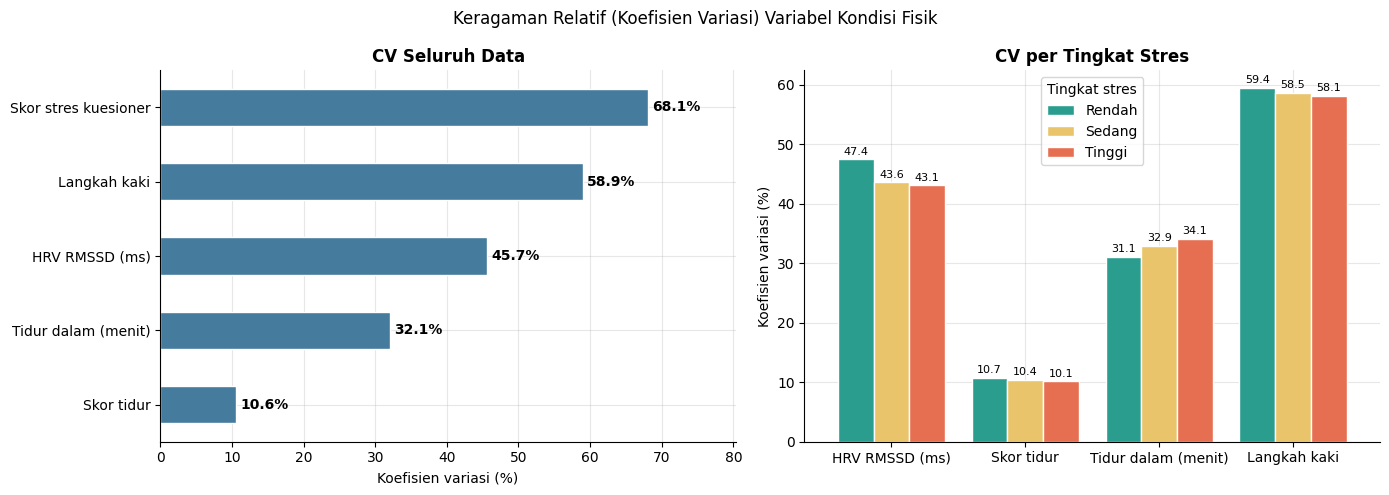

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

cv_all = bentuk["CV (%)"].astype(float).sort_values()
cv_all.plot(kind="barh", color="#457B9D", edgecolor="white", ax=ax1)
ax1.bar_label(ax1.containers[0], fmt="%.1f%%", padding=3, fontweight="bold")
ax1.set_xlim(0, cv_all.max() * 1.18); ax1.set_xlabel("Koefisien variasi (%)")
ax1.set_title("CV Seluruh Data", fontweight="bold")

cv_kat = pd.DataFrame({VAR[v]: desk_kat[v]["CV (%)"].loc[URUT] for v in VAR}).T
cv_kat.plot(kind="bar", color=WARNA, edgecolor="white", width=0.8, ax=ax2)
for c in ax2.containers:
    ax2.bar_label(c, fmt="%.1f", padding=2, fontsize=8)
ax2.set_ylabel("Koefisien variasi (%)"); ax2.set_xlabel(""); ax2.tick_params(axis="x", rotation=0)
ax2.set_title("CV per Tingkat Stres", fontweight="bold"); ax2.legend(title="Tingkat stres")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.set_axisbelow(True); ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Keragaman Relatif (Koefisien Variasi) Variabel Kondisi Fisik")
plt.tight_layout()
plt.savefig(f"{OUT}/5_koefisien_variasi.png", dpi=150, bbox_inches="tight"); plt.show()

**Kesimpulan RM 3:**
- **Keragaman relatif (CV, seluruh data):** langkah kaki paling beragam di antara variabel fisik (58,9%), diikuti HRV (45,7%), tidur dalam (32,1%), dan skor tidur paling seragam (10,6%). Skor stres kuesioner CV-nya 68,1%. CV tiap variabel hampir sama di ketiga tingkat stres (HRV 43,1–47,4%; skor tidur 10,1–10,7%; tidur dalam 31,1–34,1%; langkah kaki 58,1–59,4%).
- **Skewness (seluruh data):** HRV 0,70, skor tidur −0,63, langkah kaki 0,85, dan skor stres 0,82 tergolong cukup dekat simetris (HRV, langkah kaki, dan skor stres berekor ke kanan; skor tidur berekor ke kiri). Tidur dalam 0,16 sangat mendekati simetris.
- **Kurtosis (seluruh data):** HRV −0,28 (sedikit datar), skor tidur 0,56 (sedikit runcing), tidur dalam 0,16 dan skor stres 0,02 (mendekati 0), langkah kaki 0,85 (sedikit runcing). Semuanya berada dalam −1 sampai +1, yaitu sangat dekat dengan distribusi normal menurut acuan lembar dosen.
- **Mean vs median (seluruh data):** HRV 75,83 vs 70,02, langkah kaki 9.341,98 vs 8.509, dan skor stres 36,39 vs 31 menunjukkan mean lebih besar daripada median (miring ke kanan), sejalan dengan skewness positif. Skor tidur 76,18 vs 77 menunjukkan mean sedikit lebih kecil daripada median (miring ke kiri ringan), sejalan dengan skewness −0,63. Tidur dalam 79,04 vs 79 hampir sama, sejalan dengan skewness 0,16 yang hampir simetris.
- **Per tingkat stres**, hampir semua nilai masih dalam −2 sampai +2. Yang keluar dari −1 sampai +1: skewness langkah kaki pada stres sedang (1,07), kurtosis langkah kaki pada stres sedang (2,07) dan tinggi (1,04), serta kurtosis skor tidur pada stres sedang (1,28). Hanya kurtosis langkah kaki stres sedang (2,07) yang sedikit melewati +2, yaitu cenderung lebih runcing dan berekor berat.
- Pada data berekor kanan (HRV dan langkah kaki), rata-rata ditarik ke atas oleh sebagian kecil nilai besar, sehingga rata-rata perlu dibaca bersama median dan standar deviasinya.

## F. Kesimpulan
1. **RM 1:** dari 1.371 observasi, tingkat stres rendah paling banyak (55,1%), diikuti sedang (30,9%) dan tinggi (13,9%). Rata-rata skor stres 36,39 (SD 24,78).
2. **RM 2:** rata-rata dan penyebaran HRV, skor tidur, tidur dalam, dan langkah kaki hampir sama di ketiga tingkat stres. Selisih rata-rata antar tingkat stres jauh lebih kecil daripada standar deviasinya, dan median memberi gambaran serupa.
3. **RM 3:** langkah kaki dan HRV paling beragam (CV 58,9% dan 45,7%), sedangkan skor tidur paling seragam (CV 10,6%). Seluruh skewness dan kurtosis data keseluruhan berada dalam −1 sampai +1, artinya bentuk distribusinya dekat dengan simetris/normal menurut acuan deskriptif; ekor ke kanan pada HRV, langkah kaki, dan skor stres, ekor ke kiri pada skor tidur. Perbandingan mean dan median sejalan dengan arah skewness tersebut.

**Keterbatasan:**
1. Satu mahasiswa memiliki banyak hari pengamatan (4–90 hari), sehingga mahasiswa dengan data lebih banyak lebih berpengaruh pada rata-rata gabungan.
2. Batas kategori stres (0–33, 34–66, 67–100) adalah asumsi peneliti, sehingga jumlah observasi tiap kategori bergantung pada batas tersebut.
3. Skor stres berasal dari kuesioner laporan sendiri, sedangkan data fisik berasal dari sensor wearable.
4. Durasi tidur hanya fase tidur dalam, dan HRV yang dipakai adalah RMSSD, bukan detak jantung langsung.
5. Hasil bersifat deskriptif: "dekat dengan normal" adalah interpretasi dari skewness dan kurtosis, bukan hasil uji normalitas; hasil juga tidak menguji perbedaan antar kelompok dan tidak menunjukkan hubungan sebab-akibat.